# 02 · Exploratory Data Analysis (EDA)
**UTS Data Science – Kelas RPL (DASI) · Daniel Haganta Ginting (41426090)**

| | |
|---|---|
| **Input** | `../data/processed/01_clean.csv` (6.352 baris × 10 kolom), `../data/processed/01_cuaca_harian.csv` |
| **Output** | Grafik di `../laporan/figures/02_*.png`, ringkasan angka `../data/processed/02_ringkasan.json` |
| **Target** | `Harga_Cabai_Merah_Keriting` (Rp/kg). Fokus analisis: **Pasar Tradisional** |

## Pertanyaan analitik (dirumuskan sebelum membuat grafik)
Tujuan project adalah memprediksi harga cabai merah keriting di **Pasar Tradisional Kota Medan**, supaya pemerintah daerah,
pedagang, dan konsumen bisa mengantisipasi lonjakan harga. Lima pertanyaan berikut menuntun EDA:

1. **Q1 – Pola waktu:** Bagaimana tren dan pola musiman harga di Pasar Tradisional? Bulan apa harga biasanya tertinggi dan terendah?
2. **Q2 – Rantai pasok:** Seberapa besar selisih harga antar-level (Produsen → Pedagang Besar → Pasar Tradisional → Pasar
   Modern), dan apakah harga di hulu bergerak lebih dulu?
3. **Q3 – Cuaca:** Apakah curah hujan berhubungan dengan harga? Jika ya, dengan jeda waktu berapa lama?
4. **Q4 – Hari besar:** Apakah harga naik menjelang Idul Fitri dan hari besar lain?
5. **Q5 – Volatilitas:** Pasar mana yang harganya paling sering dan paling besar berubah?

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import holidays

PROC = Path("../data/processed")
FIG = Path("../laporan/figures")
RANDOM_STATE = 42
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "font.size": 12, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 12,
                     "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 10})
from matplotlib.ticker import FuncFormatter
RIBUAN = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))   # sumbu harga: 100000 -> 100.000

PASAR = ["Produsen", "Pedagang Besar", "Pasar Tradisional", "Pasar Modern"]
WARNA = dict(zip(PASAR, ["#2e7d32", "#f9a825", "#c62828", "#1565c0"]))
BULAN = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
HARI = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat"]
TARGET = "Harga_Cabai_Merah_Keriting"

df = pd.read_csv(PROC / "01_clean.csv", parse_dates=["Tanggal"])
df["Kategori_Pasar"] = pd.Categorical(df["Kategori_Pasar"], categories=PASAR, ordered=True)
cuaca = pd.read_csv(PROC / "01_cuaca_harian.csv", parse_dates=["Tanggal"]).set_index("Tanggal")
WMO_LABEL = {1: "Berawan", 2: "Berawan", 3: "Berawan", 51: "Gerimis", 53: "Gerimis", 55: "Gerimis",
             61: "Hujan Ringan", 63: "Hujan Sedang", 65: "Hujan Lebat"}
df["Kategori_Cuaca"] = pd.Categorical(df["Kode_Cuaca_WMO"].map(WMO_LABEL),
                                      categories=["Berawan", "Gerimis", "Hujan Ringan", "Hujan Sedang", "Hujan Lebat"], ordered=True)
df["Bulan"] = df["Tanggal"].dt.month
df["Tahun"] = df["Tanggal"].dt.year
df["Hari"] = pd.Categorical(df["Tanggal"].dt.dayofweek.map(dict(enumerate(HARI))), categories=HARI, ordered=True)
trad = df[df["Kategori_Pasar"] == "Pasar Tradisional"].set_index("Tanggal")
wide = df.pivot(index="Tanggal", columns="Kategori_Pasar", values=TARGET)[PASAR]
R = {}   # ringkasan angka untuk laporan & PPT
print(df.shape)
df.head()

(6352, 14)


,Tanggal,Kategori_Pasar,Komoditas,Harga_Cabai_Merah_Keriting,Harga_Cabai_Merah_Agregat,Kode_Cuaca_WMO,Suhu_Rata2_C,Curah_Hujan_mm,Kecepatan_Angin_Maks_kmh,Is_Imputasi,Kategori_Cuaca,Bulan,Tahun,Hari
0,2019-12-31,Pasar Modern,Cabai Merah Keriting,39550,39550,63,25.1,7.6,9.4,0,Hujan Sedang,12,2019,Selasa
1,2020-01-01,Pasar Modern,Cabai Merah Keriting,39550,39550,53,25.5,2.2,9.3,0,Gerimis,1,2020,Rabu
2,2020-01-02,Pasar Modern,Cabai Merah Keriting,39550,39550,51,25.6,0.2,7.2,0,Gerimis,1,2020,Kamis
3,2020-01-03,Pasar Modern,Cabai Merah Keriting,39550,39550,61,25.7,4.2,10.1,0,Hujan Ringan,1,2020,Jumat
4,2020-01-06,Pasar Modern,Cabai Merah Keriting,39550,39550,51,25.6,1.2,10.8,0,Gerimis,1,2020,Senin


## 1 · Analisis univariat

In [2]:
num_cols = [TARGET, "Suhu_Rata2_C", "Curah_Hujan_mm", "Kecepatan_Angin_Maks_kmh"]
def deskriptif(s):
    q1, q3 = s.quantile([.25, .75])
    return pd.Series({"count": s.count(), "mean": s.mean(), "median": s.median(), "std": s.std(), "min": s.min(),
                      "Q1": q1, "Q3": q3, "IQR": q3 - q1, "max": s.max(), "skewness": s.skew(), "kurtosis": s.kurt()})
desk = pd.DataFrame({c: deskriptif(df[c]) for c in num_cols}).T.round(2)
desk_pasar = df.groupby("Kategori_Pasar", observed=True)[TARGET].apply(deskriptif).unstack()
desk_pasar = desk_pasar.round(0).assign(skewness=desk_pasar["skewness"].round(2), kurtosis=desk_pasar["kurtosis"].round(2))
print("Statistik deskriptif kolom numerik (semua pasar):")
display(desk)
print("Statistik target per pasar:")
display(desk_pasar)
R["desk_target"] = desk.loc[TARGET].to_dict()
R["desk_pasar"] = desk_pasar[["mean", "median", "std", "IQR", "skewness", "min", "max"]].to_dict(orient="index")

Statistik deskriptif kolom numerik (semua pasar):


,count,mean,median,std,min,Q1,Q3,IQR,max,skewness,kurtosis
Harga_Cabai_Merah_Keriting,6352.0,37105.28,34450.00,18165.97,7500.0,23500.0,45500.00,22000.00,115500.0,1.09,1.31
Suhu_Rata2_C,6352.0,25.80,25.80,0.85,23.2,25.2,26.40,1.20,29.7,0.24,0.63
Curah_Hujan_mm,6352.0,12.49,10.05,11.25,0.0,3.8,18.32,14.52,129.7,2.07,10.75
Kecepatan_Angin_Maks_kmh,6352.0,10.44,10.20,2.28,4.2,8.8,11.90,3.10,19.2,0.48,0.32


Statistik target per pasar:


,count,mean,median,std,min,Q1,Q3,IQR,max,skewness,kurtosis
Kategori_Pasar,,,,,,,,,,,
Produsen,1588.0,26947.0,22000.0,14468.0,7500.0,17000.0,33000.0,16000.0,70000.0,1.49,1.88
Pedagang Besar,1588.0,32685.0,28000.0,16316.0,10000.0,21000.0,38000.0,17000.0,100000.0,1.43,2.00
Pasar Tradisional,1588.0,37853.0,33700.0,16527.0,14900.0,26600.0,44700.0,18100.0,109500.0,1.44,2.12
Pasar Modern,1588.0,50936.0,45950.0,16038.0,29250.0,40050.0,58850.0,18800.0,115500.0,1.48,2.45


**Apa:** statistik deskriptif (mean, median, std, IQR, skewness, kurtosis) untuk target dan 3 variabel cuaca, lalu target per pasar.

**Mengapa:** mean vs median dan skewness menunjukkan bentuk distribusi; IQR dipakai karena tahan outlier.

**Arti:** mean target Rp37.105 > median Rp34.450 dengan skew 1,09, jadi harga **miring ke kanan**: kebanyakan hari harga
normal, sesekali melonjak tinggi (maks Rp115.500). Di Pasar Tradisional median Rp33.700, IQR Rp18.100, skew 1,44.
Curah hujan sangat miring (skew 2,07). Suhu (std 0,85 °C) dan angin hampir simetris.

**Pengaruh:** fitur yang miring (hujan, volatilitas) ditransformasi di Tahap 3. Untuk UAS, target `log(harga)` dipertimbangkan.

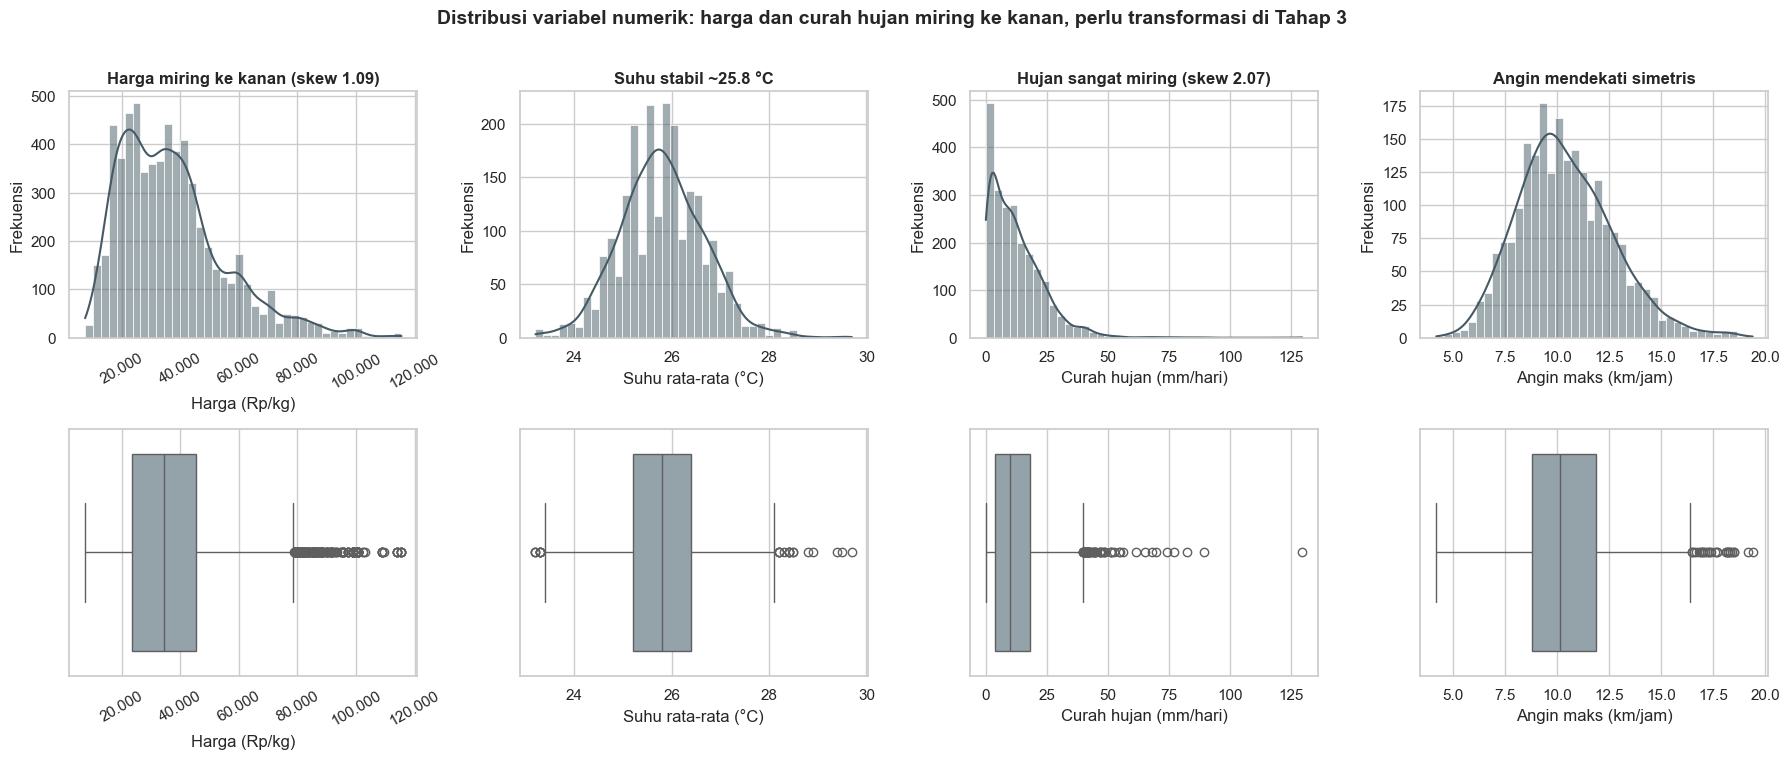

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7.5))
label = {TARGET: "Harga (Rp/kg)", "Suhu_Rata2_C": "Suhu rata-rata (°C)", "Curah_Hujan_mm": "Curah hujan (mm/hari)",
         "Kecepatan_Angin_Maks_kmh": "Angin maks (km/jam)"}
judul = {TARGET: f"Harga miring ke kanan (skew {desk.loc[TARGET,'skewness']:.2f})",
         "Suhu_Rata2_C": f"Suhu stabil ~{desk.loc['Suhu_Rata2_C','median']:.1f} °C",
         "Curah_Hujan_mm": f"Hujan sangat miring (skew {desk.loc['Curah_Hujan_mm','skewness']:.2f})",
         "Kecepatan_Angin_Maks_kmh": "Angin mendekati simetris"}
for i, c in enumerate(num_cols):
    sns.histplot(df[c] if c == TARGET else cuaca.loc[df["Tanggal"].min():, c], bins=40, kde=True, ax=axes[0, i], color="#455a64")
    axes[0, i].set_title(judul[c], fontsize=12); axes[0, i].set_xlabel(label[c]); axes[0, i].set_ylabel("Frekuensi")
    sns.boxplot(x=df[c] if c == TARGET else cuaca.loc[df["Tanggal"].min():, c], ax=axes[1, i], color="#90a4ae")
    axes[1, i].set_xlabel(label[c])
axes[0, 0].xaxis.set_major_formatter(RIBUAN); axes[1, 0].xaxis.set_major_formatter(RIBUAN)
axes[0, 0].tick_params(axis="x", rotation=30); axes[1, 0].tick_params(axis="x", rotation=30)
fig.suptitle("Distribusi variabel numerik: harga dan curah hujan miring ke kanan, perlu transformasi di Tahap 3", y=1.01, fontweight="bold", fontsize=14)
plt.tight_layout(); plt.savefig(FIG / "02_univariat_numerik.png"); plt.show()

**Arti grafik:** histogram harga punya ekor panjang ke kanan dan boxplot menampilkan banyak titik di atas pagar IQR.
Pada NB01 titik-titik ini sudah diverifikasi sebagai **lonjakan nyata** (2022 dan 2025), bukan salah input.
Histogram hujan menumpuk di 0–20 mm dengan beberapa hari ekstrem (maks 129,7 mm).
**Pengaruh:** outlier harga tetap disimpan karena justru momen lonjakan inilah yang ingin diprediksi.

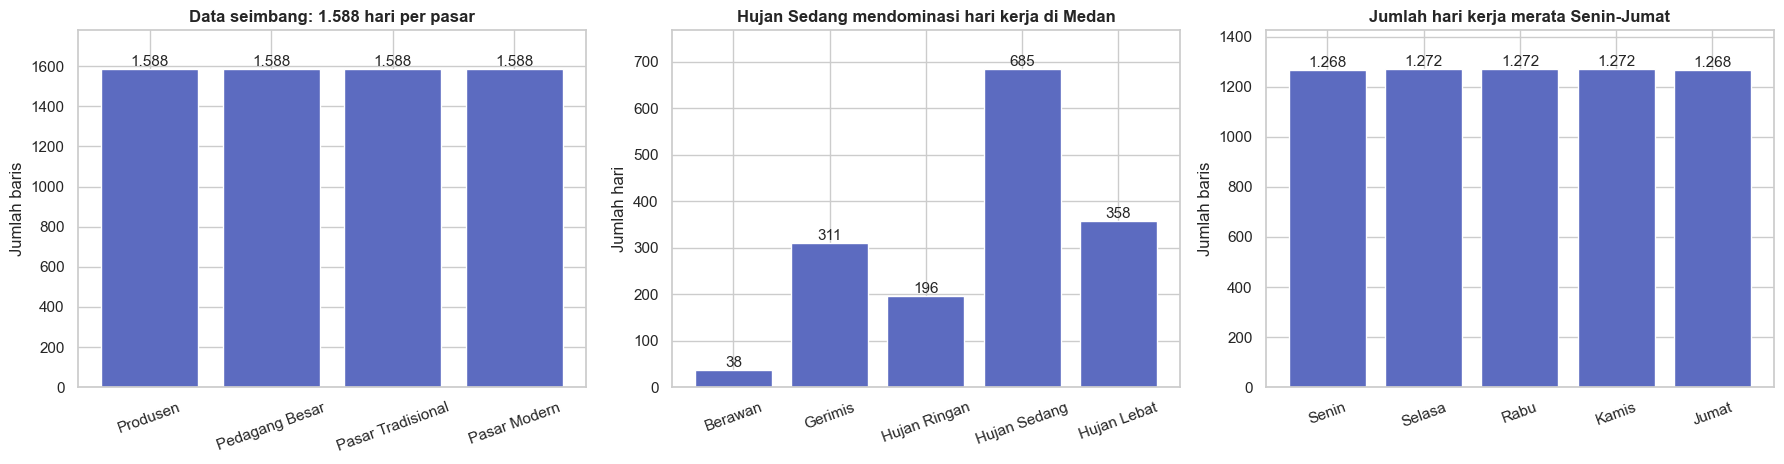

Proporsi kategori cuaca (% hari kerja): {'Hujan Sedang': 43.1, 'Hujan Lebat': 22.5, 'Gerimis': 19.6, 'Hujan Ringan': 12.3, 'Berawan': 2.4}


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, col, title in [(axes[0], "Kategori_Pasar", "Data seimbang: 1.588 hari per pasar"),
                       (axes[1], "Kategori_Cuaca", "Hujan Sedang mendominasi hari kerja di Medan"),
                       (axes[2], "Hari", "Jumlah hari kerja merata Senin-Jumat")]:
    sub = df if col != "Kategori_Cuaca" else df[df["Kategori_Pasar"] == "Pasar Tradisional"]
    vc = sub[col].value_counts().reindex(sub[col].cat.categories)
    ax.bar(vc.index.astype(str), vc.values, color="#5c6bc0")
    for j, v in enumerate(vc.values):
        ax.text(j, v, f"{v:,}".replace(",", "."), ha="center", va="bottom", fontsize=11)
    ax.set_title(title, fontsize=12); ax.set_ylim(0, vc.max() * 1.12); ax.set_ylabel("Jumlah baris" if col != "Kategori_Cuaca" else "Jumlah hari"); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(FIG / "02_univariat_kategorikal.png"); plt.show()
cuaca_pct = (df[df["Kategori_Pasar"] == "Pasar Tradisional"]["Kategori_Cuaca"].value_counts(normalize=True) * 100).round(1)
print("Proporsi kategori cuaca (% hari kerja):", cuaca_pct.to_dict())
R["cuaca_pct"] = cuaca_pct.to_dict()

**Apa:** bar chart frekuensi tiga variabel kategorikal: Kategori_Pasar, kategori cuaca (dari kode WMO), dan hari.

**Arti:** data **seimbang**, 1.588 hari per pasar, sehingga tidak ada pasar yang mendominasi model. Medan sangat basah:
Hujan Sedang 43,1% dan Hujan Lebat 22,5% hari kerja, sedangkan Berawan hanya 2,4%.

**Pengaruh:** kategori "Berawan" sangat jarang, jadi kategori cuaca diperlakukan sebagai skala ordinal (0–4), bukan 5
kolom one-hot yang sebagian besar berisi nol.

## 2 · Analisis bivariat (fitur vs target)

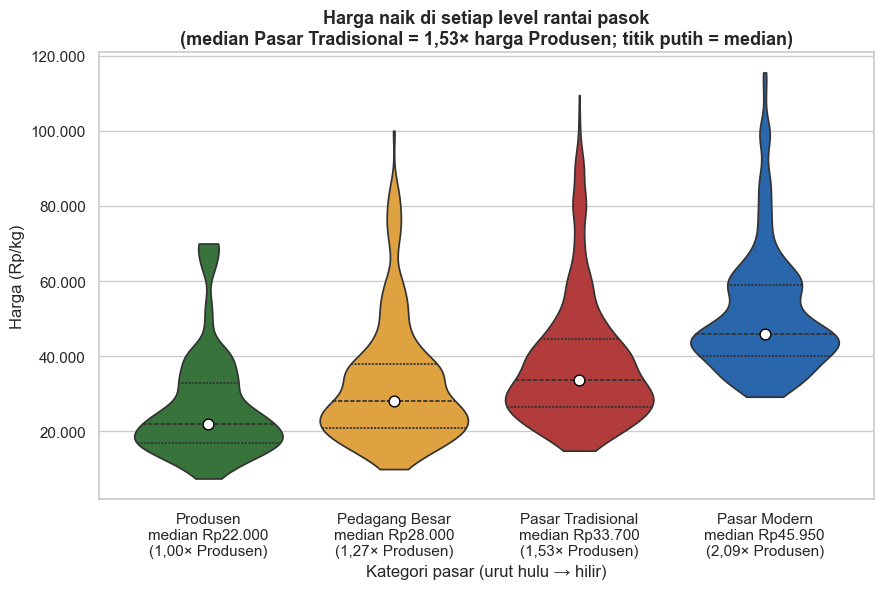

,median (Rp),rasio thd Produsen
Kategori_Pasar,,
Produsen,22000.0,1.00
Pedagang Besar,28000.0,1.27
Pasar Tradisional,33700.0,1.53
Pasar Modern,45950.0,2.09


ANOVA F = 662.2, p = 0.00e+00 | Kruskal-Wallis H = 1960.8, p = 0.00e+00


In [5]:
# Q2 – numerik vs kategorik: harga per level rantai pasok
fig, ax = plt.subplots(figsize=(10, 5.8))
sns.violinplot(data=df, x="Kategori_Pasar", y=TARGET, palette=WARNA, inner="quartile", cut=0, ax=ax)
med = df.groupby("Kategori_Pasar", observed=True)[TARGET].median()
for i, m in enumerate(PASAR):
    ax.scatter(i, med[m], s=60, color="white", edgecolor="black", zorder=3)
ax.set_xticks(range(len(PASAR)), [f"{m}\nmedian Rp{med[m]:,.0f}".replace(",", ".") + f"\n({med[m] / med['Produsen']:.2f}× Produsen)".replace(".", ",") for m in PASAR])
ax.set_title(f"Harga naik di setiap level rantai pasok\n(median Pasar Tradisional = {med['Pasar Tradisional']/med['Produsen']:.2f}× harga Produsen; titik putih = median)".replace(".", ",", 1))
ax.set_xlabel("Kategori pasar (urut hulu → hilir)"); ax.set_ylabel("Harga (Rp/kg)"); ax.yaxis.set_major_formatter(RIBUAN)
plt.savefig(FIG / "02_bivariat_harga_per_pasar.png"); plt.show()

anova = stats.f_oneway(*[g[TARGET].values for _, g in df.groupby("Kategori_Pasar", observed=True)])
kruskal = stats.kruskal(*[g[TARGET].values for _, g in df.groupby("Kategori_Pasar", observed=True)])
markup = pd.DataFrame({"median (Rp)": med, "rasio thd Produsen": (med / med["Produsen"]).round(2)})
display(markup)
print(f"ANOVA F = {anova.statistic:.1f}, p = {anova.pvalue:.2e} | Kruskal-Wallis H = {kruskal.statistic:.1f}, p = {kruskal.pvalue:.2e}")
R["median_pasar"] = med.to_dict(); R["rasio_trad_produsen"] = round(med["Pasar Tradisional"] / med["Produsen"], 2)
R["anova_pasar_F"] = round(float(anova.statistic), 1)

**Apa:** violin plot harga per level rantai pasok, plus uji ANOVA dan Kruskal-Wallis (versi non-parametrik, karena data tidak normal).

**Arti:** harga naik bertahap: Produsen Rp22.000 → Pedagang Besar Rp28.000 (1,27×) → **Pasar Tradisional Rp33.700 (1,53×)** →
Pasar Modern Rp45.950 (2,09×). Perbedaannya sangat signifikan (ANOVA F = 662,2; Kruskal H = 1.960,8; p ≈ 0).

**Pengaruh:** `Kategori_Pasar` wajib menjadi fitur (one-hot + ordinal `Level_Rantai_Pasok` di Tahap 3). Tanpa fitur ini,
model akan mencampur 4 level harga yang berbeda jauh.

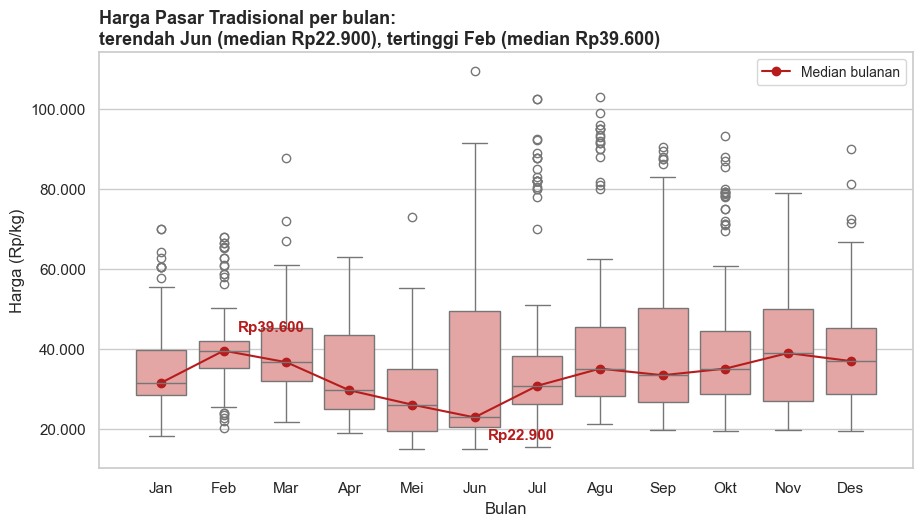

Kruskal-Wallis harga antar bulan (Pasar Tradisional): H = 134.8, p = 1.83e-23
Median per bulan: {1: 31550.0, 2: 39600.0, 3: 36700.0, 4: 29700.0, 5: 26100.0, 6: 22900.0, 7: 30800.0, 8: 35100.0, 9: 33450.0, 10: 35100.0, 11: 39000.0, 12: 37000.0}


In [6]:
# Q1 – numerik vs kategorik (waktu): harga Pasar Tradisional per bulan
fig, ax = plt.subplots(figsize=(10.5, 5.4))
sns.boxplot(data=trad.reset_index(), x="Bulan", y=TARGET, color="#ef9a9a", ax=ax, showfliers=True)
bulan_med = trad.groupby("Bulan")[TARGET].median()
ax.plot(range(12), bulan_med.values, color="#b71c1c", marker="o", label="Median bulanan")
ax.set_xticks(range(12), BULAN)
lo, hi = bulan_med.idxmin(), bulan_med.idxmax()
rb = lambda v: f"{v:,.0f}".replace(",", ".")
ax.set_title(f"Harga Pasar Tradisional per bulan:\nterendah {BULAN[lo-1]} (median Rp{rb(bulan_med[lo])}), "
             f"tertinggi {BULAN[hi-1]} (median Rp{rb(bulan_med[hi])})", loc="left")
for b in (lo, hi):
    ax.annotate(f"Rp{bulan_med[b]:,.0f}".replace(",", "."), (b - 1, bulan_med[b]), xytext=(34, -16 if b == lo else 14),
                textcoords="offset points", ha="center", fontsize=11, fontweight="bold", color="#b71c1c")
ax.set_xlabel("Bulan"); ax.set_ylabel("Harga (Rp/kg)"); ax.yaxis.set_major_formatter(RIBUAN); ax.legend(loc="upper right")
plt.savefig(FIG / "02_bivariat_harga_per_bulan.png"); plt.show()
kw_bulan = stats.kruskal(*[g[TARGET].values for _, g in trad.groupby("Bulan")])
print(f"Kruskal-Wallis harga antar bulan (Pasar Tradisional): H = {kw_bulan.statistic:.1f}, p = {kw_bulan.pvalue:.2e}")
print("Median per bulan:", bulan_med.to_dict())
R["bulan_terendah"] = BULAN[lo-1]; R["bulan_tertinggi"] = BULAN[hi-1]
R["median_bulan_terendah"] = float(bulan_med[lo]); R["median_bulan_tertinggi"] = float(bulan_med[hi])
R["kw_bulan_p"] = float(kw_bulan.pvalue)

**Apa (Q1):** distribusi harga Pasar Tradisional per bulan kalender.

**Arti:** ada pola musiman yang signifikan (Kruskal-Wallis H = 134,8; p = 1,8e-23). Median terendah di **Juni (Rp22.900)**,
yang merupakan musim panen raya. Median tertinggi di **Februari (Rp39.600)** dan November (Rp39.000), saat musim hujan dan
paceklik. Kotak di setiap bulan tetap lebar, jadi bulan saja tidak cukup untuk menjelaskan harga.

**Pengaruh:** dibuat fitur `Bulan`, `Bulan_sin/cos` (siklik), dan target encoding `TE_Pasar_Bulan` di Tahap 3.

Korelasi terkuat: {'jendela_hari': 60.0, 'lag_minggu': 11.0, 'spearman': 0.20034270510310048, 'p_value': 7.682457756292379e-16, 'n': 1588.0}
Hujan hari yang sama vs harga: rho = 0.100, p = 0.000


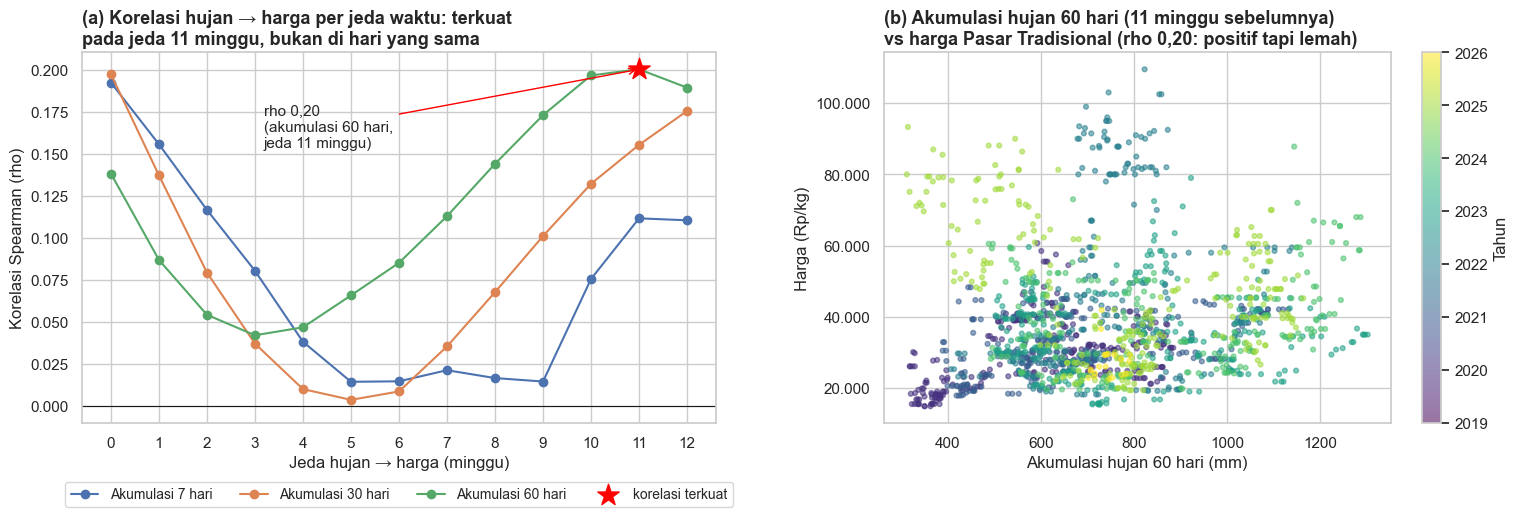

In [7]:
# Q3 – numerik vs numerik: akumulasi hujan vs harga, dengan berbagai jeda (lag)
hujan_harian = cuaca["Curah_Hujan_mm"]
hasil_lag = []
for window in (7, 30, 60):
    akumulasi = hujan_harian.rolling(window, min_periods=window).sum()
    for lag_minggu in range(0, 13):
        x = akumulasi.shift(lag_minggu * 7).reindex(trad.index)
        ok = x.notna()
        rho, p = stats.spearmanr(x[ok], trad.loc[ok, TARGET])
        hasil_lag.append({"jendela_hari": window, "lag_minggu": lag_minggu, "spearman": rho, "p_value": p, "n": int(ok.sum())})
hasil_lag = pd.DataFrame(hasil_lag)
best = hasil_lag.loc[hasil_lag["spearman"].idxmax()]
print("Korelasi terkuat:", best.to_dict())
same_day = stats.spearmanr(trad["Curah_Hujan_mm"], trad[TARGET])
print(f"Hujan hari yang sama vs harga: rho = {same_day.statistic:.3f}, p = {same_day.pvalue:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.4))
for w, g in hasil_lag.groupby("jendela_hari"):
    axes[0].plot(g["lag_minggu"], g["spearman"], marker="o", label=f"Akumulasi {w} hari")
axes[0].axhline(0, color="k", lw=0.8)
axes[0].scatter(best["lag_minggu"], best["spearman"], s=260, marker="*", color="red", zorder=4, label="korelasi terkuat")
axes[0].annotate(f"rho {best['spearman']:.2f}\n(akumulasi {int(best['jendela_hari'])} hari,\njeda {int(best['lag_minggu'])} minggu)".replace(".", ","),
                 (best["lag_minggu"], best["spearman"]), xytext=(-270, -25), textcoords="offset points", fontsize=11, va="top",
                 arrowprops=dict(arrowstyle="->", color="red"))
axes[0].set_title(f"(a) Korelasi hujan → harga per jeda waktu: terkuat\npada jeda {int(best['lag_minggu'])} minggu, bukan di hari yang sama", loc="left")
axes[0].set_xlabel("Jeda hujan → harga (minggu)"); axes[0].set_ylabel("Korelasi Spearman (rho)"); axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=4, fontsize=10); axes[0].set_xticks(range(0, 13))
x_best = hujan_harian.rolling(int(best["jendela_hari"])).sum().shift(int(best["lag_minggu"]) * 7).reindex(trad.index)
sc = axes[1].scatter(x_best, trad[TARGET], s=12, alpha=0.55, c=trad.index.year, cmap="viridis")
plt.colorbar(sc, ax=axes[1], label="Tahun")
axes[1].set_title(f"(b) Akumulasi hujan {int(best['jendela_hari'])} hari ({int(best['lag_minggu'])} minggu sebelumnya)\nvs harga Pasar Tradisional (rho {best['spearman']:.2f}: positif tapi lemah)".replace("0.", "0,"), loc="left")
axes[1].yaxis.set_major_formatter(RIBUAN)
axes[1].set_xlabel(f"Akumulasi hujan {int(best['jendela_hari'])} hari (mm)"); axes[1].set_ylabel("Harga (Rp/kg)")
plt.tight_layout(); plt.savefig(FIG / "02_bivariat_hujan_lag_harga.png"); plt.show()
R["hujan_best"] = {k: (float(v) if not isinstance(v, str) else v) for k, v in best.to_dict().items()}
R["hujan_same_day_rho"] = round(float(same_day.statistic), 3); R["hujan_same_day_p"] = round(float(same_day.pvalue), 3)

**Apa (Q3):** korelasi Spearman antara akumulasi hujan (7/30/60 hari) dan harga Pasar Tradisional dengan jeda 0–12 minggu,
ditambah scatter untuk jeda terbaik.

**Mengapa:** hujan tidak langsung menaikkan harga. Hujan merusak bunga dan buah cabai lalu memicu penyakit, sehingga pasokan
baru turun beberapa minggu kemudian. Karena itu jeda diuji secara sistematis.

**Arti:** hujan di hari yang sama hampir tidak berkaitan (rho 0,10). Korelasi terkuat ada pada **akumulasi hujan 60 hari
dengan jeda 11 minggu (rho 0,20; p = 7,7e-16)**, sesuai siklus tanam–panen cabai (±3 bulan). Hubungannya positif tetapi
lemah, dan scatter tetap menyebar.

**Pengaruh:** dibuat fitur `Akumulasi_Hujan_60H_Lag11Mgg` dan akumulasi 7/30 hari di Tahap 3. Kolom cuaca hari-H
dibuang karena tidak informatif dan bukan informasi H-1.

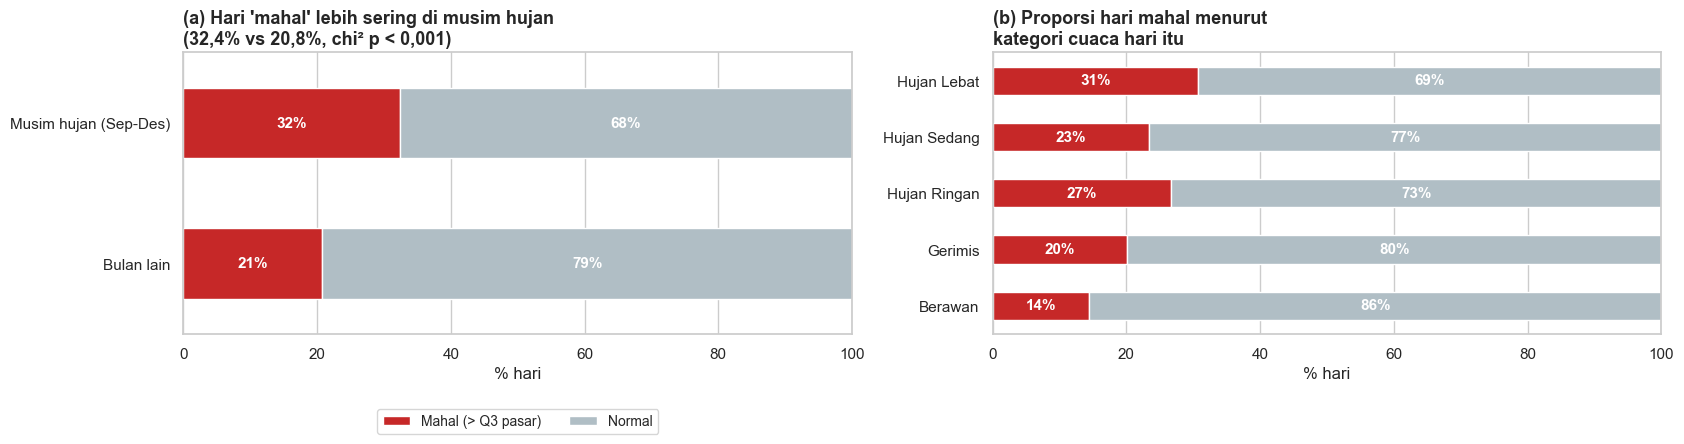

Status_Harga,Mahal (> Q3 pasar),Normal
Musim,,
Bulan lain,20.8,79.2
Musim hujan (Sep-Des),32.4,67.6


Status_Harga,Mahal (> Q3 pasar),Normal
Kategori_Cuaca,,
Berawan,14.5,85.5
Gerimis,20.1,79.9
Hujan Ringan,26.7,73.3
Hujan Sedang,23.4,76.6
Hujan Lebat,30.7,69.3


Chi-square Musim x Status_Harga: chi2 = 101.6, p = 6.84e-24


In [8]:
# kategorik vs kategorik: musim & kategori cuaca vs status harga (di atas Q3 pasar masing-masing = "mahal")
df["Status_Harga"] = np.where(df[TARGET] > df.groupby("Kategori_Pasar", observed=True)[TARGET].transform("quantile", 0.75), "Mahal (> Q3 pasar)", "Normal")
df["Musim"] = np.where(df["Bulan"].isin([9, 10, 11, 12]), "Musim hujan (Sep-Des)", "Bulan lain")
ct = pd.crosstab(df["Musim"], df["Status_Harga"], normalize="index") * 100
ct2 = pd.crosstab(df["Kategori_Cuaca"], df["Status_Harga"], normalize="index") * 100
chi = stats.chi2_contingency(pd.crosstab(df["Musim"], df["Status_Harga"]))
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
ct.plot(kind="barh", stacked=True, color=["#c62828", "#b0bec5"], ax=axes[0])
axes[0].set_title(f"(a) Hari 'mahal' lebih sering di musim hujan\n({ct.loc['Musim hujan (Sep-Des)','Mahal (> Q3 pasar)']:.1f}% vs {ct.loc['Bulan lain','Mahal (> Q3 pasar)']:.1f}%, chi² p < 0,001)".replace(".", ","), loc="left")
axes[0].set_xlabel("% hari"); axes[0].set_ylabel("")
ct2.plot(kind="barh", stacked=True, color=["#c62828", "#b0bec5"], ax=axes[1], legend=False)
axes[1].set_title("(b) Proporsi hari mahal menurut\nkategori cuaca hari itu", loc="left"); axes[1].set_xlabel("% hari"); axes[1].set_ylabel("")
for a in axes:
    for cont in a.containers:
        a.bar_label(cont, labels=[f"{w:.0f}%" for w in cont.datavalues], label_type="center", color="white", fontsize=11, fontweight="bold")
    a.set_xlim(0, 100)
axes[0].legend(loc="lower center", bbox_to_anchor=(0.5, -0.38), ncol=2, title=None)
plt.tight_layout(); plt.savefig(FIG / "02_bivariat_kategorik_crosstab.png"); plt.show()
display(ct.round(1)); display(ct2.round(1))
print(f"Chi-square Musim x Status_Harga: chi2 = {chi[0]:.1f}, p = {chi[1]:.2e}")
R["mahal_musim_hujan"] = round(float(ct.loc["Musim hujan (Sep-Des)", "Mahal (> Q3 pasar)"]), 1)
R["mahal_bulan_lain"] = round(float(ct.loc["Bulan lain", "Mahal (> Q3 pasar)"]), 1)
R["chi_musim_p"] = float(chi[1])

**Apa:** crosstab (kategorik vs kategorik) antara musim dan kategori cuaca dengan status harga ("mahal" = di atas Q3 pasarnya
sendiri), diuji dengan chi-square.

**Arti:** proporsi hari mahal **32,4% di Sep–Des vs 20,8% di bulan lain** (chi² = 101,6; p = 6,8e-24). Menurut kategori
cuaca hari itu, hari mahal paling sering saat Hujan Lebat (30,7%) dan paling jarang saat Berawan (14,5%).

**Pengaruh:** dibuat flag `Is_Musim_Hujan` dan diskretisasi intensitas hujan BMKG di Tahap 3.

## 3 · Analisis multivariat

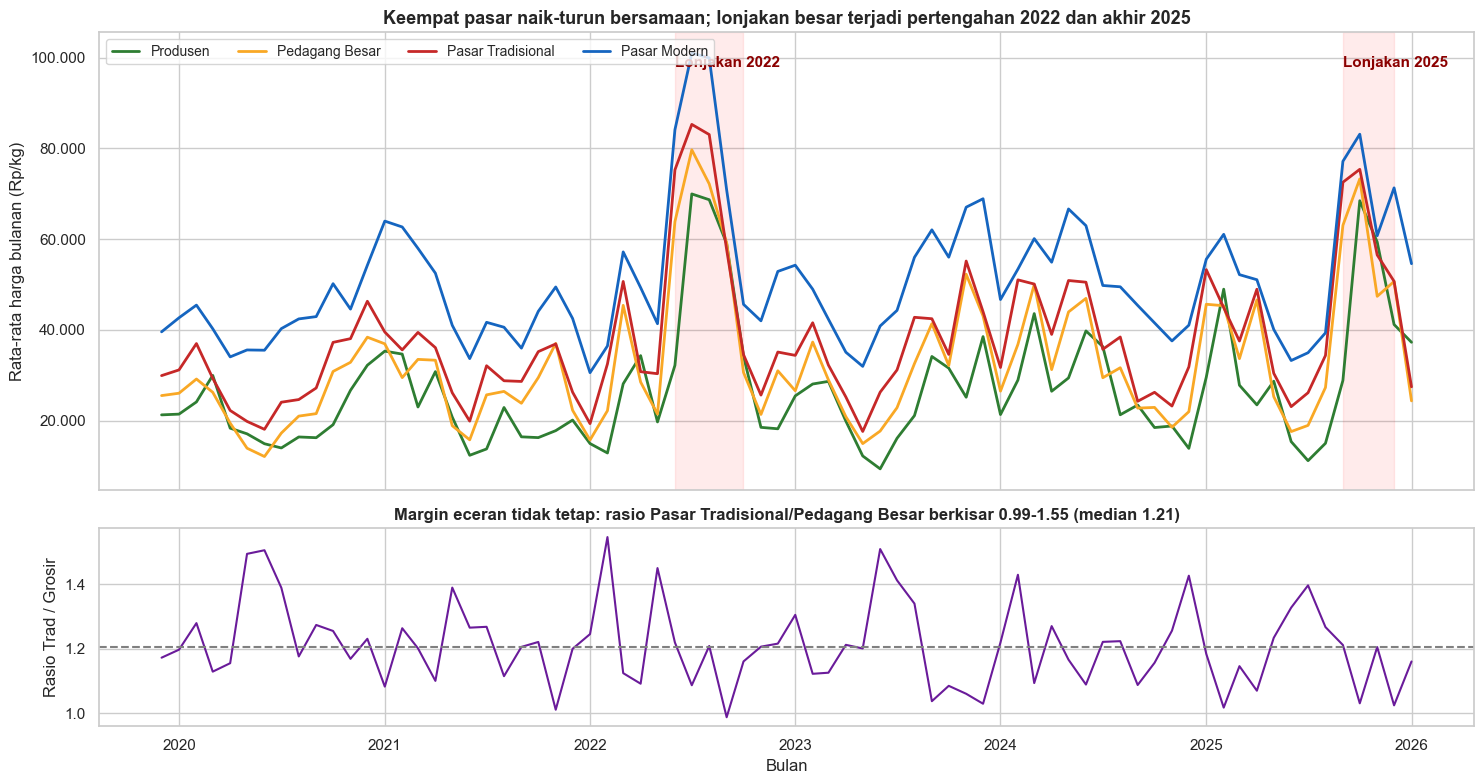

Korelasi harga antar pasar (Spearman):


Kategori_Pasar,Produsen,Pedagang Besar,Pasar Tradisional,Pasar Modern
Kategori_Pasar,,,,
Produsen,1.000,0.700,0.627,0.720
Pedagang Besar,0.700,1.000,0.890,0.831
Pasar Tradisional,0.627,0.890,1.000,0.814
Pasar Modern,0.720,0.831,0.814,1.000


In [9]:
# Multivariat 1 (hue): tren bulanan 4 pasar + rasio Pasar Tradisional / Pedagang Besar
bulanan = df.groupby([pd.Grouper(key="Tanggal", freq="MS"), "Kategori_Pasar"], observed=True)[TARGET].mean().unstack()[PASAR]
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
for m in PASAR:
    axes[0].plot(bulanan.index, bulanan[m], label=m, color=WARNA[m], lw=2)
for a, b, t in [("2022-06-01", "2022-09-30", "Lonjakan 2022"), ("2025-09-01", "2025-11-30", "Lonjakan 2025")]:
    axes[0].axvspan(pd.Timestamp(a), pd.Timestamp(b), color="red", alpha=0.08)
    axes[0].text(pd.Timestamp(a), bulanan.max().max() * 0.97, t, fontsize=11, color="darkred", fontweight="bold")
axes[0].set_title("Keempat pasar naik-turun bersamaan; lonjakan besar terjadi pertengahan 2022 dan akhir 2025")
axes[0].set_ylabel("Rata-rata harga bulanan (Rp/kg)"); axes[0].legend(ncol=4, loc="upper left"); axes[0].yaxis.set_major_formatter(RIBUAN)
rasio = (wide["Pasar Tradisional"] / wide["Pedagang Besar"]).resample("MS").mean()
axes[1].plot(rasio.index, rasio, color="#6a1b9a"); axes[1].axhline(rasio.median(), ls="--", color="gray")
axes[1].set_ylabel("Rasio Trad / Grosir"); axes[1].set_xlabel("Bulan")
axes[1].set_title(f"Margin eceran tidak tetap: rasio Pasar Tradisional/Pedagang Besar berkisar {rasio.min():.2f}-{rasio.max():.2f} (median {rasio.median():.2f})", fontsize=12)
plt.tight_layout(); plt.savefig(FIG / "02_multivariat_tren_pasar.png"); plt.show()
print("Korelasi harga antar pasar (Spearman):")
display(wide.corr(method="spearman").round(3))
R["rasio_trad_pb_median"] = round(float(rasio.median()), 2); R["rasio_trad_pb_min"] = round(float(rasio.min()), 2); R["rasio_trad_pb_max"] = round(float(rasio.max()), 2)
R["puncak_bulanan_trad"] = {"bulan": f"{bulanan['Pasar Tradisional'].idxmax():%Y-%m}", "harga": round(float(bulanan['Pasar Tradisional'].max()), 0)}

**Apa (multivariat 1, waktu × harga × pasar):** tren rata-rata bulanan ke-4 pasar dan rasio Pasar Tradisional/Pedagang Besar.

**Arti:** keempat pasar bergerak searah. Puncak Pasar Tradisional terjadi pada **Juli 2022 (rata-rata Rp85.267/kg)**.
Korelasi Spearman Pasar Tradisional paling tinggi dengan **Pedagang Besar (0,89)**, lebih tinggi daripada dengan Produsen (0,63).
Artinya harga eceran lebih mengikuti harga grosir dibanding harga di petani. Margin eceran tidak tetap: rasio Trad/Grosir
bergerak 0,99–1,55 (median 1,21).

**Pengaruh:** dibuat fitur antar-kelompok `Harga_PB_Lag1`, `Harga_Produsen_Lag1`, dan `Rasio_Thd_Grosir_Lag1`.

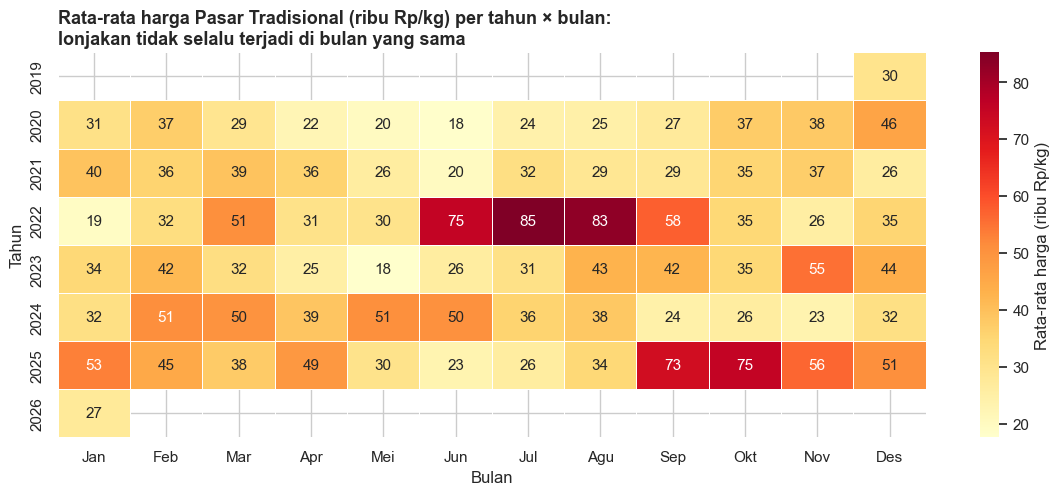

In [10]:
# Multivariat 2 (heatmap pivot): Tahun x Bulan, harga rata-rata Pasar Tradisional
pivot = trad.pivot_table(index="Tahun", columns="Bulan", values=TARGET, aggfunc="mean")
pivot.columns = [BULAN[c - 1] for c in pivot.columns]
fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(pivot / 1000, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label": "Rata-rata harga (ribu Rp/kg)"}, ax=ax, linewidths=.5, annot_kws={"fontsize": 11})
ax.set_title("Rata-rata harga Pasar Tradisional (ribu Rp/kg) per tahun × bulan:\nlonjakan tidak selalu terjadi di bulan yang sama", loc="left")
ax.set_xlabel("Bulan"); ax.set_ylabel("Tahun")
plt.savefig(FIG / "02_multivariat_heatmap_tahun_bulan.png"); plt.show()

**Apa (multivariat 2, tahun × bulan × harga):** heatmap rata-rata harga Pasar Tradisional.

**Arti:** lonjakan tidak selalu jatuh di bulan yang sama. Tahun 2022 memuncak pada Jun–Agu, sedangkan 2025 pada Sep–Nov.
Pola musiman ada, tetapi bergeser dari tahun ke tahun.

**Pengaruh:** model tidak bisa hanya mengandalkan kalender. Fitur yang mengikuti kondisi terkini (lag, moving average,
momentum) dan kondisi hujan beberapa bulan sebelumnya tetap diperlukan.

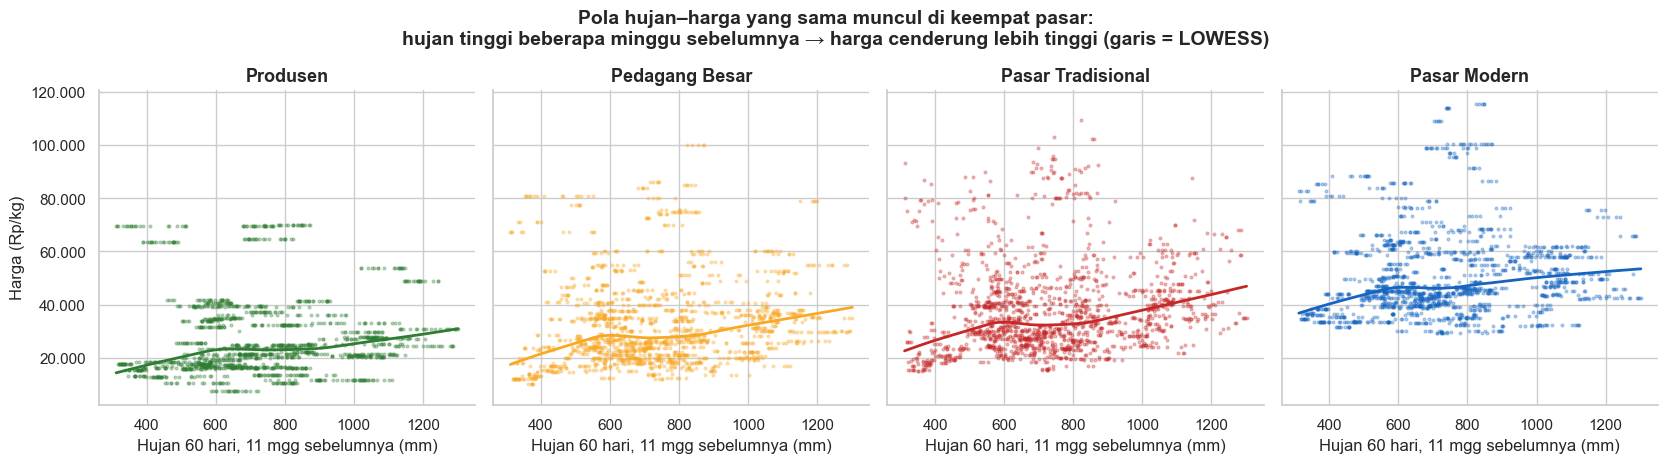

In [11]:
# Multivariat 3 (facet): hubungan hujan 60 hari (lag terbaik) dengan harga, per pasar
x_lag = hujan_harian.rolling(int(best["jendela_hari"])).sum().shift(int(best["lag_minggu"]) * 7)
df["Hujan_lag_terbaik"] = x_lag.reindex(df["Tanggal"]).values
g = sns.lmplot(data=df.dropna(subset=["Hujan_lag_terbaik"]), x="Hujan_lag_terbaik", y=TARGET, col="Kategori_Pasar", hue="Kategori_Pasar",
               palette=WARNA, col_wrap=4, height=4.2, scatter_kws={"s": 4, "alpha": .3}, line_kws={"lw": 2}, lowess=True)
g.set_axis_labels(f"Hujan {int(best['jendela_hari'])} hari, {int(best['lag_minggu'])} mgg sebelumnya (mm)", "Harga (Rp/kg)")
for a in g.axes.flat:
    a.yaxis.set_major_formatter(RIBUAN)
g.set_titles("{col_name}", size=13, weight="bold")
g.fig.suptitle("Pola hujan–harga yang sama muncul di keempat pasar:\nhujan tinggi beberapa minggu sebelumnya → harga cenderung lebih tinggi (garis = LOWESS)", y=1.1, fontweight="bold", fontsize=14)
plt.savefig(FIG / "02_multivariat_facet_hujan_pasar.png"); plt.show()

**Apa (multivariat 3, facet):** hubungan hujan 60 hari (jeda 11 minggu) dengan harga, dipisah per pasar, dengan garis LOWESS.

**Arti:** kemiringan positif muncul di keempat pasar, jadi efek hujan bersifat umum dan bukan kebetulan di satu pasar.
Level harganya berbeda per pasar.

**Pengaruh:** cukup satu fitur hujan yang sama untuk semua pasar. Perbedaan level harga ditangani oleh fitur pasar.

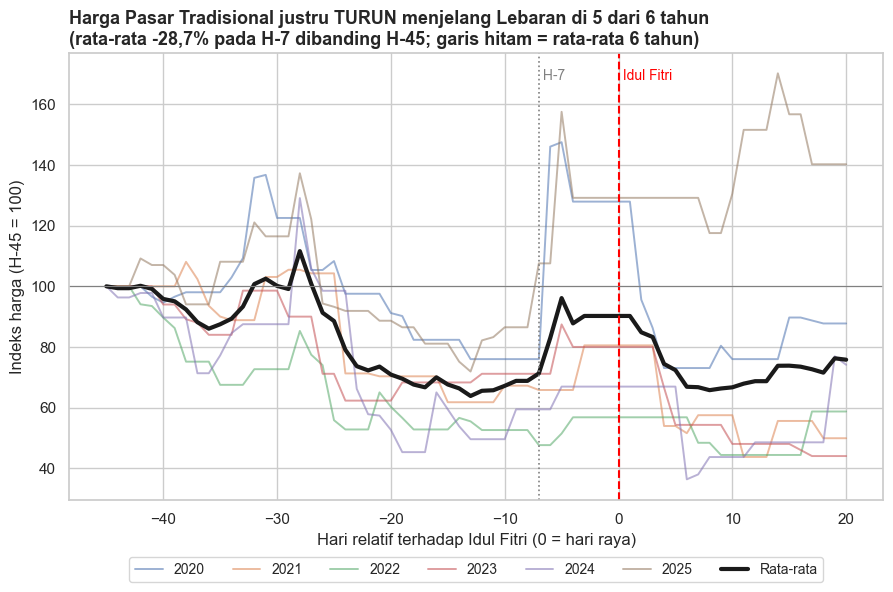

Perubahan H-7 vs H-45 per tahun (%): {2020: -24.0, 2021: -34.2, 2022: -52.4, 2023: -28.9, 2024: -40.6, 2025: 7.6}
Median Desember Rp37,000 vs bulan lain Rp33,600


In [12]:
# Q4 – Event study menjelang Idul Fitri (indeks harga relatif terhadap 45 hari kalender sebelum Lebaran)
libur = holidays.country_holidays("ID", years=range(2020, 2027))
idul_fitri = sorted(d for d, n in libur.items() if "Hari Raya Idul Fitri" in n.split("; "))
rows = []
trad_daily = trad[TARGET].asfreq("D").ffill()
for h in idul_fitri:
    h = pd.Timestamp(h)
    if h - pd.Timedelta(days=45) < trad_daily.index.min() or h + pd.Timedelta(days=20) > trad_daily.index.max():
        continue
    base = trad_daily.loc[h - pd.Timedelta(days=45)]
    for d in range(-45, 21):
        rows.append({"Tahun": h.year, "hari_ke": d, "indeks": trad_daily.loc[h + pd.Timedelta(days=d)] / base * 100})
ev = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(10.5, 5.8))
for y, g in ev.groupby("Tahun"):
    ax.plot(g["hari_ke"], g["indeks"], alpha=.55, lw=1.4, label=str(y))
rata = ev.groupby("hari_ke")["indeks"].mean()
ax.plot(rata.index, rata.values, color="k", lw=3, label="Rata-rata")
ax.axvline(0, color="red", ls="--"); ax.axhline(100, color="gray", lw=.8)
naik = rata.loc[-7] - 100
per_tahun = ev[ev["hari_ke"] == -7].set_index("Tahun")["indeks"].round(1) - 100
ax.axvline(-7, color="gray", ls=":", lw=1.2); ax.text(-7, ax.get_ylim()[1] * 0.97, " H-7", fontsize=10, color="gray", va="top")
ax.text(0, ax.get_ylim()[1] * 0.97, " Idul Fitri", fontsize=10, color="red", va="top")
ax.set_title(f"Harga Pasar Tradisional justru TURUN menjelang Lebaran di {(per_tahun < 0).sum()} dari {len(per_tahun)} tahun\n"
             f"(rata-rata {naik:+.1f}% pada H-7 dibanding H-45; garis hitam = rata-rata 6 tahun)".replace(".", ","), loc="left")
ax.set_xlabel("Hari relatif terhadap Idul Fitri (0 = hari raya)"); ax.set_ylabel("Indeks harga (H-45 = 100)"); ax.legend(ncol=7, fontsize=10, loc="lower center", bbox_to_anchor=(0.5, -0.2))
plt.savefig(FIG / "02_event_study_idul_fitri.png"); plt.show()
print("Perubahan H-7 vs H-45 per tahun (%):", per_tahun.round(1).to_dict())
R["lebaran_rata_h7"] = round(float(naik), 1); R["lebaran_per_tahun"] = per_tahun.to_dict()
R["lebaran_tahun_naik"] = int((per_tahun > 0).sum()); R["lebaran_jumlah_tahun"] = int(len(per_tahun))

# Desember (Natal-Tahun Baru) vs bulan lain
des = trad[trad.index.month == 12][TARGET].median(); lain = trad[trad.index.month != 12][TARGET].median()
print(f"Median Desember Rp{des:,.0f} vs bulan lain Rp{lain:,.0f}")
R["median_des"] = float(des); R["median_non_des"] = float(lain)

**Apa (Q4):** event study. Harga Pasar Tradisional diindeks terhadap H-45 sebelum Idul Fitri (6 tahun: 2020–2025),
lalu dibandingkan median Desember dengan bulan lain.

**Arti:** berlawanan dengan anggapan umum, harga pada H-7 justru **lebih rendah daripada H-45 di 5 dari 6 tahun**
(rata-rata −28,7%). Hanya 2025 yang naik (+7,6%). Lonjakan biasanya sudah terjadi sebelum atau di awal Ramadan, lalu
turun mendekati Lebaran. Desember sedikit lebih mahal (median Rp37.000 vs Rp33.600).

**Pengaruh:** fitur hari besar tetap dibuat (`Hari_Menuju_Idul_Fitri`, `Is_Ramadan`, `Is_Menjelang_Hari_Besar`),
tetapi diperkirakan arahnya bisa negatif. Kegunaannya diuji di Tahap 4, bukan diasumsikan.

,% hari harga berubah,std perubahan harian (%),perubahan harian maks (%),hari berubah > 5%
Kategori_Pasar,,,,
Produsen,4.6,13.01,253.2,66
Pedagang Besar,17.8,11.70,133.3,244
Pasar Tradisional,57.3,11.20,92.3,553
Pasar Modern,13.0,6.39,113.7,146


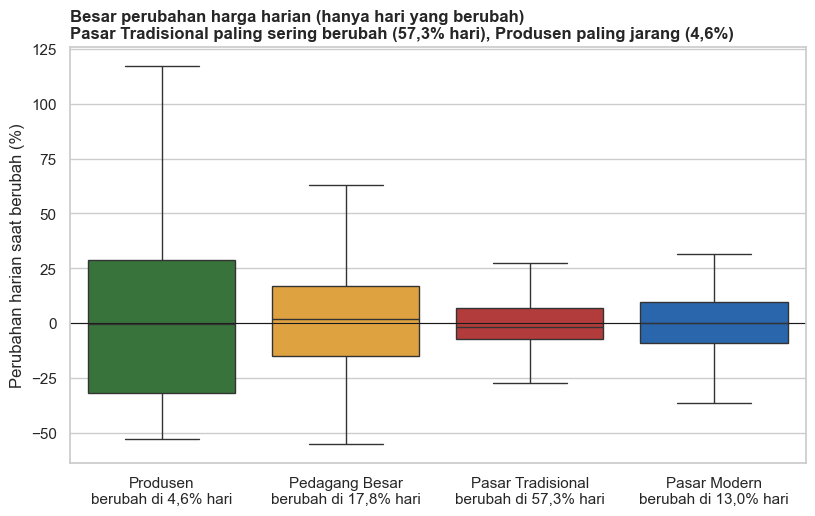

Tanggal (hari ke-) perubahan harga Produsen: {25: 44, 27: 12, 26: 12, 28: 1, 24: 1}
Korelasi perubahan Pedagang Besar (geser k hari) dgn perubahan Pasar Tradisional: {0: 0.003, 1: -0.002, 2: -0.018, 3: -0.014, 4: -0.032, 5: 0.003}
Autokorelasi harga Pasar Tradisional (lag hari kerja): {1: 0.961, 5: 0.861, 20: 0.556, 60: 0.065}


In [13]:
# Q5 – Volatilitas harian per pasar
ret = wide.pct_change() * 100
vol = pd.DataFrame({
    "% hari harga berubah": ((wide.diff() != 0).iloc[1:].mean() * 100).round(1),
    "std perubahan harian (%)": ret.std().round(2),
    "perubahan harian maks (%)": ret.abs().max().round(1),
    "hari berubah > 5%": (ret.abs() > 5).sum(),
}).reindex(PASAR)
display(vol)
fig, ax = plt.subplots(figsize=(9.5, 5.4))
sns.boxplot(data=ret.melt(var_name="Pasar", value_name="ret").dropna().query("ret != 0"), x="Pasar", y="ret", palette=WARNA, ax=ax, showfliers=False)
ax.set_title(f"Besar perubahan harga harian (hanya hari yang berubah)\nPasar Tradisional paling sering berubah ({vol.loc['Pasar Tradisional','% hari harga berubah']:.1f}% hari), "
             f"Produsen paling jarang ({vol.loc['Produsen','% hari harga berubah']:.1f}%)".replace(".", ","), loc="left", fontsize=12)
ax.set_xticks(range(len(PASAR)), [f"{m}\nberubah di {vol.loc[m, '% hari harga berubah']:.1f}% hari".replace(".", ",") for m in PASAR])
ax.axhline(0, color="k", lw=.8)
ax.set_ylabel("Perubahan harian saat berubah (%)"); ax.set_xlabel("")
plt.savefig(FIG / "02_volatilitas_pasar.png"); plt.show()
prod_change = wide["Produsen"].diff().ne(0)
hari_bulan = wide.index[prod_change & (wide.index > wide.index[0])].day
print("Tanggal (hari ke-) perubahan harga Produsen:", pd.Series(hari_bulan).value_counts().head(5).to_dict())
R["volatilitas"] = vol.to_dict(orient="index")
R["produsen_berubah_tgl_25_27"] = int(pd.Series(hari_bulan).between(24, 28).sum()); R["produsen_jumlah_berubah"] = int(len(hari_bulan))

# Apakah perubahan di hulu mendahului Pasar Tradisional? korelasi silang perubahan harian
lead = {k: round(float(ret["Pedagang Besar"].shift(k).corr(ret["Pasar Tradisional"])), 3) for k in range(0, 6)}
print("Korelasi perubahan Pedagang Besar (geser k hari) dgn perubahan Pasar Tradisional:", lead)
autocorr = {k: round(float(trad[TARGET].autocorr(k)), 3) for k in (1, 5, 20, 60)}
print("Autokorelasi harga Pasar Tradisional (lag hari kerja):", autocorr)
R["lead_pb_trad"] = lead; R["autocorr_trad"] = autocorr

**Apa (Q5):** frekuensi dan besar perubahan harga harian per pasar, korelasi silang perubahan Pedagang Besar → Pasar
Tradisional, dan autokorelasi harga.

**Arti:**
- Pasar Tradisional berubah di **57,3% hari** (553 hari berubah >5%). Produsen hanya 4,6%, dan 70 dari 73 perubahannya
  terjadi pada tanggal 24–28. Ini menandakan harga Produsen di PIHPS **dicatat bulanan**, bukan harian.
- Perubahan harian Pedagang Besar **tidak mendahului** perubahan Pasar Tradisional (korelasi ≈ 0 untuk jeda 0–5 hari).
  Kaitannya ada pada level harga, bukan pada perubahan harian.
- Autokorelasi Pasar Tradisional sangat tinggi: lag-1 0,961, lag-5 0,861, lag-20 0,556, lalu hilang pada lag-60 (0,065).

**Pengaruh:** fitur lag 1/5/20 dan MA7/MA20 adalah kandidat terkuat. Fitur Produsen kurang informatif untuk dinamika harian.
Baseline "harga kemarin" wajib dipakai sebagai pembanding model di UAS.

## 4 · Pemeriksaan asumsi

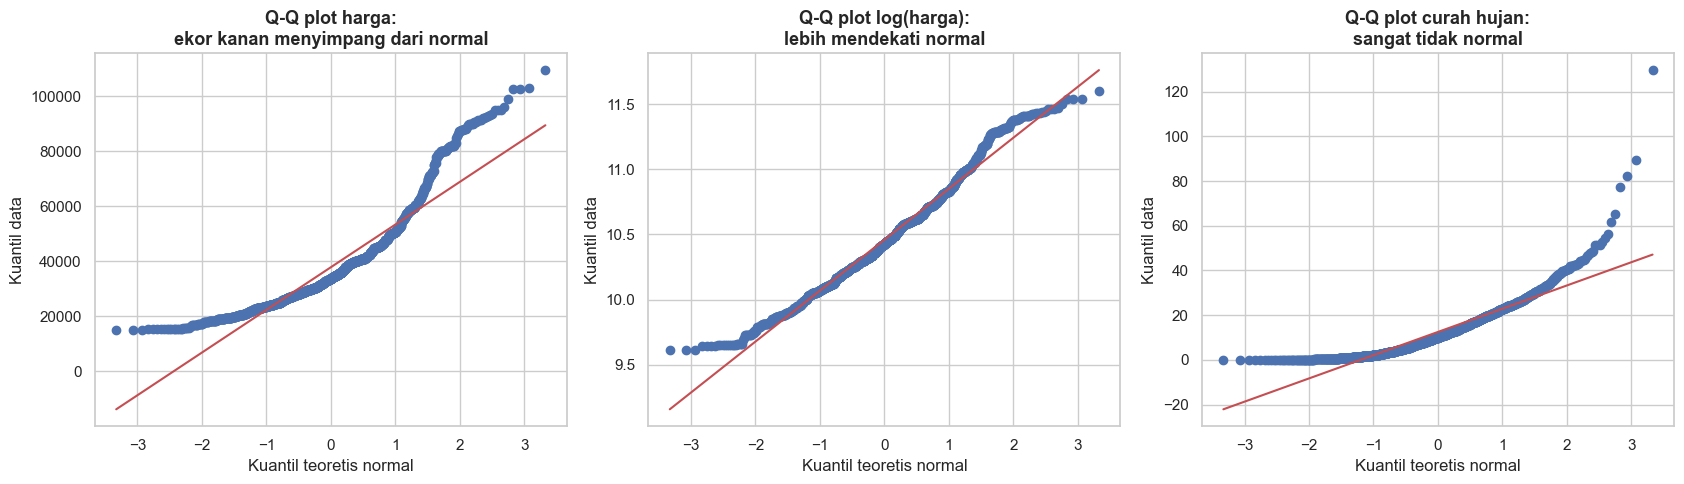

,Variabel,Shapiro W (n=500),p-value,skewness (semua data),"Normal (alpha 0,05)?"
0,Harga Pasar Tradisional,0.8641,0.0000,1.4432,Tidak
1,log(Harga) Pasar Tradisional,0.9784,0.0000,0.4074,Tidak
2,Curah hujan,0.7837,0.0000,2.0763,Tidak
3,Suhu,0.9912,0.0046,0.2358,Tidak


Keseimbangan kelas target: tidak berlaku (regresi). Komposisi baris per pasar seimbang: {'Produsen': 1588, 'Pedagang Besar': 1588, 'Pasar Tradisional': 1588, 'Pasar Modern': 1588}


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
y = trad[TARGET]
stats.probplot(y, dist="norm", plot=axes[0]); axes[0].set_title("Q-Q plot harga:\nekor kanan menyimpang dari normal")
stats.probplot(np.log(y), dist="norm", plot=axes[1]); axes[1].set_title("Q-Q plot log(harga):\nlebih mendekati normal")
stats.probplot(trad["Curah_Hujan_mm"], dist="norm", plot=axes[2]); axes[2].set_title("Q-Q plot curah hujan:\nsangat tidak normal")
for a in axes: a.set_xlabel("Kuantil teoretis normal"); a.set_ylabel("Kuantil data")
plt.tight_layout(); plt.savefig(FIG / "02_qqplot_normalitas.png"); plt.show()

sampel = trad.sample(500, random_state=RANDOM_STATE)
uji = pd.DataFrame({
    "Variabel": ["Harga Pasar Tradisional", "log(Harga) Pasar Tradisional", "Curah hujan", "Suhu"],
    "Shapiro W (n=500)": [stats.shapiro(sampel[TARGET])[0], stats.shapiro(np.log(sampel[TARGET]))[0],
                          stats.shapiro(sampel["Curah_Hujan_mm"])[0], stats.shapiro(sampel["Suhu_Rata2_C"])[0]],
    "p-value": [stats.shapiro(sampel[TARGET])[1], stats.shapiro(np.log(sampel[TARGET]))[1],
                stats.shapiro(sampel["Curah_Hujan_mm"])[1], stats.shapiro(sampel["Suhu_Rata2_C"])[1]],
    "skewness (semua data)": [y.skew(), np.log(y).skew(), trad["Curah_Hujan_mm"].skew(), trad["Suhu_Rata2_C"].skew()],
})
uji["Normal (alpha 0,05)?"] = np.where(uji["p-value"] > 0.05, "Ya", "Tidak")
display(uji.round(4))
print("Keseimbangan kelas target: tidak berlaku (regresi). Komposisi baris per pasar seimbang:", df["Kategori_Pasar"].value_counts().to_dict())
R["shapiro"] = uji.set_index("Variabel")[["Shapiro W (n=500)", "p-value", "skewness (semua data)"]].round(4).to_dict(orient="index")

**Apa:** Q-Q plot dan uji Shapiro-Wilk pada sampel n = 500 (random_state = 42). Sampel dipakai karena Shapiro terlalu
sensitif untuk n besar.

**Arti:** tidak ada variabel yang normal (p < 0,05). Transformasi log menurunkan skewness harga Pasar Tradisional dari
1,44 menjadi 0,41 (W naik dari 0,864 menjadi 0,978), jadi distribusinya jauh lebih mendekati normal. Target regresi tidak
memiliki "kelas", dan jumlah baris per pasar seimbang (1.588).

**Pengaruh:** korelasi utama memakai **Spearman** dan uji beda memakai Kruskal-Wallis (non-parametrik). Fitur miring
ditransformasi Yeo-Johnson di Tahap 3. `log(harga)` dicatat sebagai opsi target untuk model linear di UAS.

In [15]:
(PROC / "02_ringkasan.json").write_text(json.dumps(R, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print(json.dumps(R, indent=2, ensure_ascii=False, default=str)[:6000])

{
  "desk_target": {
    "count": 6352.0,
    "mean": 37105.28,
    "median": 34450.0,
    "std": 18165.97,
    "min": 7500.0,
    "Q1": 23500.0,
    "Q3": 45500.0,
    "IQR": 22000.0,
    "max": 115500.0,
    "skewness": 1.09,
    "kurtosis": 1.31
  },
  "desk_pasar": {
    "Produsen": {
      "mean": 26947.0,
      "median": 22000.0,
      "std": 14468.0,
      "IQR": 16000.0,
      "skewness": 1.49,
      "min": 7500.0,
      "max": 70000.0
    },
    "Pedagang Besar": {
      "mean": 32685.0,
      "median": 28000.0,
      "std": 16316.0,
      "IQR": 17000.0,
      "skewness": 1.43,
      "min": 10000.0,
      "max": 100000.0
    },
    "Pasar Tradisional": {
      "mean": 37853.0,
      "median": 33700.0,
      "std": 16527.0,
      "IQR": 18100.0,
      "skewness": 1.44,
      "min": 14900.0,
      "max": 109500.0
    },
    "Pasar Modern": {
      "mean": 50936.0,
      "median": 45950.0,
      "std": 16038.0,
      "IQR": 18800.0,
      "skewness": 1.48,
      "min": 29250.0,


## 5 · Jawaban pertanyaan analitik
| Pertanyaan | Jawaban singkat (berdasarkan output di atas) |
|---|---|
| Q1 Pola waktu | Musiman signifikan (p = 1,8e-23). Termurah Juni (median Rp22.900), termahal Februari (Rp39.600). Puncak bulanan Juli 2022 (Rp85.267). |
| Q2 Rantai pasok | Pasar Tradisional 1,53× Produsen dan rasio ±1,21× Pedagang Besar. Harga eceran paling erat dengan grosir (rho 0,89), tetapi perubahan grosir tidak mendahului eceran secara harian. |
| Q3 Cuaca | Hujan hari-H lemah (rho 0,10). Akumulasi hujan 60 hari dengan jeda 11 minggu paling kuat (rho 0,20). Hari mahal lebih sering di Sep–Des (32,4% vs 20,8%). |
| Q4 Hari besar | Harga H-7 Lebaran justru lebih rendah dari H-45 di 5 dari 6 tahun (rata-rata −28,7%). Desember sedikit lebih mahal. |
| Q5 Volatilitas | Pasar Tradisional paling sering berubah (57,3% hari). Produsen praktis dicatat bulanan (4,6%). |

## 6 · Insight (Observasi → Bukti → Implikasi)

**Insight 1 – Harga sangat bergantung pada harga sebelumnya.**
- *Observasi:* harga Pasar Tradisional bergerak lambat dan bertahap.
- *Bukti:* autokorelasi lag-1 = 0,961, lag-5 = 0,861, lag-20 = 0,556.
- *Implikasi:* fitur `Harga_Lag1/5/20` dan `Harga_MA7/MA20` dibuat di Tahap 3. Model UAS harus mengalahkan baseline
  "harga kemarin" agar benar-benar berguna.

**Insight 2 – Efek hujan tertunda sekitar 3 bulan.**
- *Observasi:* hujan hari ini tidak langsung menaikkan harga.
- *Bukti:* rho hujan hari-H = 0,10, sedangkan akumulasi 60 hari dengan jeda 11 minggu = 0,20 (p = 7,7e-16). Pola yang sama
  muncul di keempat pasar.
- *Implikasi:* fitur `Akumulasi_Hujan_60H_Lag11Mgg` dibuat. Untuk Dinas/TPID, curah hujan tinggi bisa menjadi **peringatan dini
  ±11 minggu** sebelum harga naik.

**Insight 3 – Pasar Tradisional mengikuti grosir, bukan petani.**
- *Observasi:* eceran tradisional lebih dekat ke Pedagang Besar.
- *Bukti:* Spearman Trad–PB 0,89 vs Trad–Produsen 0,63. Rasio Trad/PB 0,99–1,55 (median 1,21).
- *Implikasi:* fitur `Harga_PB_Lag1` dan `Rasio_Thd_Grosir_Lag1` dibuat. Pemantauan harga grosir lebih relevan untuk
  memperkirakan harga eceran.

**Insight 4 – Lebaran bukan pemicu kenaikan harga menjelang hari H.**
- *Observasi:* harga cenderung turun pada pekan-pekan terakhir sebelum Idul Fitri.
- *Bukti:* indeks H-7 vs H-45 turun di 5 dari 6 tahun (rata-rata −28,7%). Hanya 2025 yang naik +7,6%.
- *Implikasi:* fitur kalender dibuat, tetapi efeknya divalidasi di Tahap 4. Operasi pasar sebaiknya dimulai **sebelum/awal
  Ramadan**, bukan pada pekan terakhir.

**Insight 5 – Musim hujan (Sep–Des) meningkatkan peluang harga mahal.**
- *Observasi:* hari dengan harga di atas Q3 lebih sering terjadi pada Sep–Des.
- *Bukti:* 32,4% vs 20,8% (chi² = 101,6; p = 6,8e-24). Hari Hujan Lebat 30,7% mahal vs Berawan 14,5%.
- *Implikasi:* flag `Is_Musim_Hujan`, diskretisasi hujan BMKG, dan interaksi `Harga_Lag1 × Is_Musim_Hujan` dibuat.

**Insight 6 – Harga miring ke kanan dan Produsen dicatat bulanan.**
- *Observasi:* distribusi harga tidak normal, dan harga Produsen jarang berubah.
- *Bukti:* skew Pasar Tradisional 1,44, turun menjadi 0,41 setelah log. Produsen berubah hanya di 4,6% hari, dan 70 dari 73
  perubahannya terjadi pada tanggal 24–28.
- *Implikasi:* korelasi memakai Spearman, dan `log(harga)` dipertimbangkan untuk UAS. Fitur dari Produsen diperkirakan
  lemah untuk prediksi harian, dan ini diverifikasi di Tahap 4.